# Ecommerce Customer Behavior, Churn, and Support Analysis

This notebook uses SQL for customer-level metrics and Pandas/Matplotlib/Seaborn for the follow-up analysis. The accompanying CSV files are **synthetic data** created to match the tables and columns queried below.

The notebook expects a MySQL database named `orders_database` with `orders_1` and `support_tickets`. The main analysis period is 2026, through **October 17, 2026** in the supplied dataset.

## 1. Setup and Data Access

The connection settings can be provided through environment variables. Defaults retain the original local connection settings.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import mysql.connector
import seaborn as sns
from datetime import timedelta

In [2]:
def db_connection():
    connect = mysql.connector.connect(
        host=os.getenv("DB_HOST", "localhost"),
        port=int(os.getenv("DB_PORT", "3307")),
        password=os.getenv("DB_PASSWORD", ""),
        user=os.getenv("DB_USER", "root"),
        database=os.getenv("DB_NAME", "orders_db"))
    cursor = connect.cursor(dictionary=True)
    return connect, cursor

In [3]:
def sql_to_df(sql):
    connect, cursor = db_connection()
    try:
        cursor.execute(sql)
        result = cursor.fetchall()
        df = pd.DataFrame(result)
    finally:
        cursor.close()
        connect.close()
    return df

## 2. Purchase Behavior and Churn

These cells calculate the typical gap between repeat purchases and define an operational churn flag based on more than 70 days since the customer's last order.

### Average Days Between Repeat Orders

In [4]:
# Average days between repeat orders in 2026
sql = '''WITH returned_customers AS (
    SELECT customer_id
    FROM (
        SELECT customer_id, COUNT(*) AS count_orders
        FROM orders_1
        WHERE YEAR(order_date) = 2026
        GROUP BY customer_id
        HAVING COUNT(*) > 1
    ) t
)
SELECT AVG(days_between_orders) AS AVG_days_between_orders
FROM (
    SELECT customer_id,
           order_date,
           LEAD(order_date) OVER (PARTITION BY customer_id ORDER BY order_date) AS next_order,
           DATEDIFF(
               LEAD(order_date) OVER (PARTITION BY customer_id ORDER BY order_date),
               order_date
           ) AS days_between_orders
    FROM orders_1
    WHERE YEAR(order_date) = 2026
      AND customer_id IN (SELECT customer_id FROM returned_customers)
) t'''
connect, cursor = db_connection()
try:
    cursor.execute(sql)
    result = cursor.fetchall()
finally:
    cursor.close()
    connect.close()

AVG_Days_between_orders = (
    int(round(float(result[0]['AVG_days_between_orders'])))
    if result and result[0]['AVG_days_between_orders'] is not None
    else None
)
AVG_Days_between_orders

30

### Key Insights

- Customers with repeat orders in 2026 placed consecutive orders an average of **30 days apart**. This provides a practical starting point for the timing of repeat-purchase reminders.
- The current churn flag requires more than 70 days of inactivity—over twice the observed average interval. That creates a useful inactivity screen, but the average alone does not show the full spread of customer purchase cycles; validate the threshold across customer groups before relying on it for decisions.

### Customer Churn Status

`is_churned = 1` means the customer's last order is more than 70 days before the latest order date in the 2026 dataset. This is a working business rule, not confirmed account cancellation.

In [5]:
sql = '''WITH max_order AS (
    SELECT customer_id, MAX(order_date) AS last_order
    FROM orders_1
    WHERE YEAR(order_date) = 2026
    GROUP BY customer_id
),
recency_table AS (
    SELECT *,
           DATEDIFF(
               (SELECT MAX(order_date) FROM orders_1 WHERE YEAR(order_date) = 2026),
               last_order
           ) AS recency
    FROM max_order
)
SELECT *,
       CASE WHEN recency > 70 THEN 1 ELSE 0 END AS is_churned
FROM recency_table'''
churn_df = sql_to_df(sql)
churn_df

,customer_id,last_order,recency,is_churned
0,CUST-10000,2026-10-17 20:00:00,0,0
1,CUST-10001,2026-09-28 07:47:09,19,0
2,CUST-10002,2026-08-30 08:02:52,48,0
3,CUST-10003,2026-08-30 14:35:24,48,0
4,CUST-10004,2026-09-30 11:16:43,17,0
...,...,...,...,...
1195,CUST-11195,2026-07-13 21:35:05,96,1
1196,CUST-11196,2026-10-01 02:58:06,16,0
1197,CUST-11197,2026-09-30 05:14:50,17,0
1198,CUST-11198,2026-08-22 17:25:36,56,0


In [6]:
churn_df['last_order'] = pd.to_datetime(churn_df['last_order'])
customer_numbers = len(churn_df)
churn_num = churn_df[churn_df['is_churned'] == 1]['customer_id'].count()
not_churn_num = churn_df[churn_df['is_churned'] == 0]['customer_id'].count()

<Axes: title={'center': 'Customer Churn Status'}, ylabel='count'>

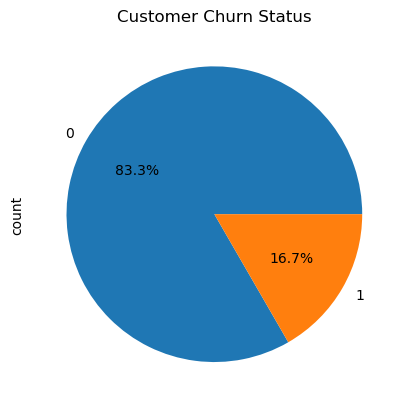

In [7]:
churn_df['is_churned'].value_counts().plot(
    kind='pie', title='Customer Churn Status', autopct='%1.1f%%'
)

### Key Insights

- **200 of 1,200 customers (16.7%)** meet the notebook's inactivity-based churn rule; the remaining **1,000 (83.3%)** do not.
- The flagged group is large enough to support a focused retention review rather than a blanket campaign to the full customer base. Because the flag is based on recency, it should be treated as a risk indicator—not proof that a customer has permanently left.

### Estimated Month of Crossing the Churn Threshold

The date below is estimated as the last order date plus 71 days, aligned with the `recency > 70` rule. It is not an observed customer event.

In [8]:
df_churn = churn_df[churn_df['is_churned'] == 1].copy()
df_churn['last_order'] = pd.to_datetime(df_churn['last_order'])
# A customer crosses the current churn rule after 71 days without another order.
df_churn['churn_date'] = df_churn['last_order'] + timedelta(days=71)
df_churn

,customer_id,last_order,recency,is_churned,churn_date
8,CUST-10008,2026-03-10 07:38:07,221,1,2026-05-20 07:38:07
12,CUST-10012,2026-06-11 04:10:24,128,1,2026-08-21 04:10:24
21,CUST-10021,2026-07-25 12:56:34,84,1,2026-10-04 12:56:34
41,CUST-10041,2026-07-21 23:47:55,88,1,2026-09-30 23:47:55
42,CUST-10042,2026-02-27 03:59:46,232,1,2026-05-09 03:59:46
...,...,...,...,...,...
1172,CUST-11172,2026-06-14 11:54:26,125,1,2026-08-24 11:54:26
1183,CUST-11183,2026-05-26 19:29:36,144,1,2026-08-05 19:29:36
1184,CUST-11184,2026-05-13 02:03:34,157,1,2026-07-23 02:03:34
1187,CUST-11187,2026-07-09 06:32:41,100,1,2026-09-18 06:32:41


   churn_month  customers_churned
0            3                  2
1            4                  9
2            5                 17
3            6                 22
4            7                 27
5            8                 52
6            9                 44
7           10                 27


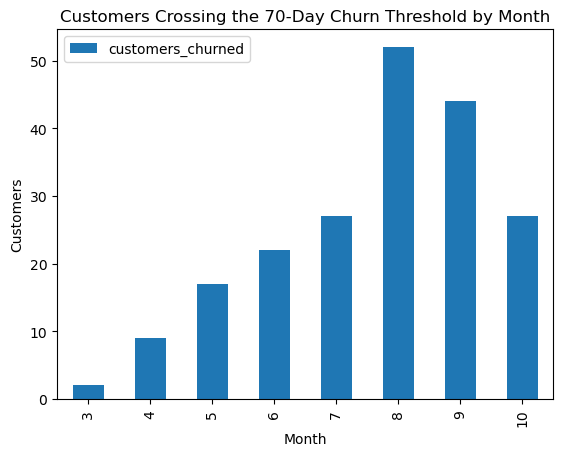

In [9]:
churn_dfmonth_churn = df_churn.groupby(df_churn['churn_date'].dt.month).agg(
    {'customer_id': 'count'}
).reset_index()
churn_dfmonth_churn.columns = ['churn_month', 'customers_churned']
print(churn_dfmonth_churn)
ax = churn_dfmonth_churn.plot.bar(x='churn_month', y='customers_churned')
_ = ax.set(title='Customers Crossing the 70-Day Churn Threshold by Month', xlabel='Month', ylabel='Customers')

### Key Insights

- Estimated threshold crossings peak in **August (52 customers)** and **September (44)**. Together, these months account for **96 of the 200 flagged customers (48%)**.
- This concentration suggests reviewing customers whose last purchases fell roughly 71 days before those estimated dates and testing earlier re-engagement reminders. The dates are calculated from `last_order + 71 days`; they represent when customers cross the notebook's inactivity rule, not observed cancellation events.

## 3. Customer Cohort Retention

Customers are grouped by the month of their first 2026 order. The heatmap shows how many customers from each cohort placed orders in subsequent months.

In [10]:
sql = '''with first_order AS (select customer_id, 
        min(order_date) first_purchase from orders_1 
        where year(order_date) = 2026
        group by customer_id),
        orders_data AS (
        select customer_id , order_date from orders_1 where year(order_date) = 2026),
        cohort_data AS (
        select  
	 o.customer_id,
	 f.first_purchase,
	 o.order_date,
	 month(first_purchase) AS cohort_month, 
     month(order_date) - month(first_purchase) + 1 AS cohort_index
     from orders_data o 
     join first_order f
     on o.customer_id = f.customer_id)
     
     select cohort_month, cohort_index, count(distinct(customer_id)) AS count_customers from cohort_data
     group by cohort_month, cohort_index
 '''
df_cohort = sql_to_df(sql)

In [11]:
df_cohort = df_cohort.pivot(index = 'cohort_month' , columns = 'cohort_index', values = 'count_customers')
df_cohort

cohort_index,1,2,3,4,5,6,7,8,9,10
cohort_month,,,,,,,,,,
1,123.0,77.0,96.0,93.0,83.0,85.0,87.0,81.0,83.0,53.0
2,116.0,70.0,75.0,81.0,69.0,77.0,80.0,71.0,42.0,NaN
3,145.0,97.0,98.0,107.0,97.0,94.0,96.0,65.0,NaN,NaN
4,137.0,85.0,94.0,92.0,91.0,88.0,61.0,NaN,NaN,NaN
5,121.0,70.0,80.0,68.0,70.0,53.0,NaN,NaN,NaN,NaN
6,123.0,78.0,78.0,82.0,55.0,NaN,NaN,NaN,NaN,NaN
7,96.0,58.0,60.0,42.0,NaN,NaN,NaN,NaN,NaN,NaN
8,143.0,73.0,68.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,123.0,54.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Text(0.5, 1.0, 'Customer Retention Cohort Analysis')

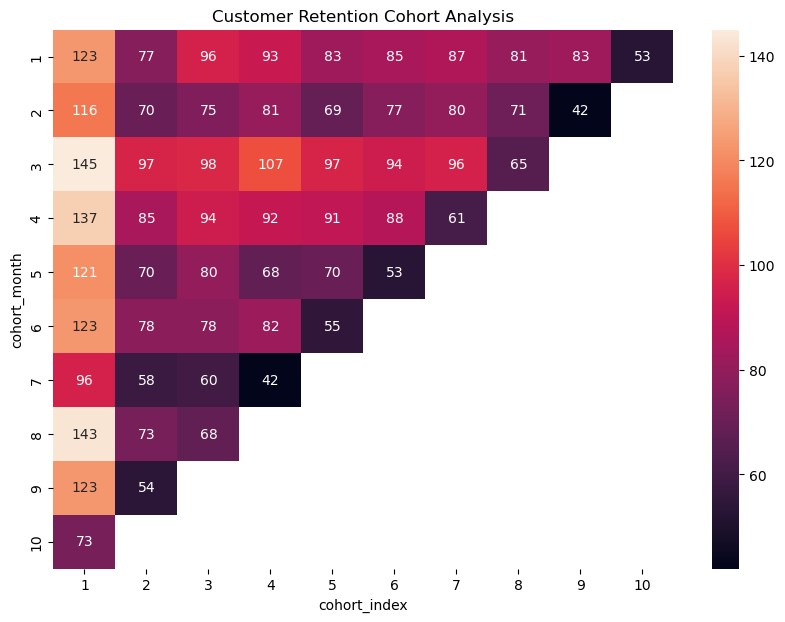

In [12]:
plt.figure(figsize = (10,7))
sns.heatmap(df_cohort,
            annot = True, 
           fmt = '.0f')
plt.title('Customer Retention Cohort Analysis')

### Key Insights

- In every cohort with a second-month observation, the active-customer count is below its first-month baseline. For example, the March cohort goes from **145 to 97 customers** (about **67%** of its starting cohort), while September goes from **123 to 54** (about **44%**).
- The displayed heatmap contains **counts, not a normalized retention-rate measure**. Later cohorts also have fewer observed months, and October has no second-month observation yet. Compare percentages over equivalent cohort ages before deciding whether the differences reflect a sustained retention problem.

## 4. RFM Customer Segmentation

Recency, Frequency, and Monetary value are scored into quintiles (`NTILE(5)`) and mapped to the segment labels in the original analysis. The RFM metrics use 2026 orders.

In [13]:
sql = '''WITH RFM AS (
    SELECT customer_id,
           COUNT(*) AS frequency,
           SUM(amount) AS monetary_value,
           DATEDIFF(
               (SELECT MAX(order_date) FROM orders_1 WHERE YEAR(order_date) = 2026),
               MAX(order_date)
           ) AS recency,
           SUM(amount) / COUNT(*) AS AOV
    FROM orders_1
    WHERE YEAR(order_date) = 2026
    GROUP BY customer_id
),
RFM_score AS (
    SELECT *,
           NTILE(5) OVER (ORDER BY frequency, customer_id) AS f_score,
           NTILE(5) OVER (ORDER BY monetary_value, customer_id) AS m_score,
           NTILE(5) OVER (ORDER BY recency DESC, customer_id) AS r_score
    FROM RFM
),
customers_segmentation AS (
    SELECT *,
           CASE
               WHEN f_score >= 4 AND m_score >= 4 AND r_score >= 4 THEN 'Champions'
               WHEN f_score >= 4 AND r_score >= 3 THEN 'Loyal Customers'
               WHEN f_score = 1 AND r_score = 5 THEN 'New Customers'
               WHEN f_score BETWEEN 2 AND 3 AND r_score >= 4 THEN 'Potential Loyalist'
               WHEN f_score >= 4 AND r_score BETWEEN 1 AND 2 AND m_score >= 4 THEN 'Can''t Lose Them'
               WHEN f_score >= 3 AND r_score BETWEEN 1 AND 2 THEN 'At Risk'
               WHEN f_score BETWEEN 1 AND 2 AND r_score = 2 THEN 'Hibernating'
               WHEN f_score BETWEEN 1 AND 2 AND r_score = 1 THEN 'Lost Customers'
               ELSE 'Others'
           END AS customers_seg
    FROM RFM_score
)
SELECT * FROM customers_segmentation'''
df_RFM = sql_to_df(sql)
df_RFM

,customer_id,frequency,monetary_value,recency,AOV,f_score,m_score,r_score,customers_seg
0,CUST-10858,1,1189.92,282,1189.920000,1,2,1,Lost Customers
1,CUST-10645,1,607.33,279,607.330000,1,1,1,Lost Customers
2,CUST-10476,1,670.80,266,670.800000,1,1,1,Lost Customers
3,CUST-10662,1,288.67,264,288.670000,1,1,1,Lost Customers
4,CUST-10524,1,531.33,253,531.330000,1,1,1,Lost Customers
...,...,...,...,...,...,...,...,...,...
1195,CUST-11053,13,10167.21,0,782.093077,5,5,5,Champions
1196,CUST-11106,4,1398.40,0,349.600000,3,2,5,Potential Loyalist
1197,CUST-11110,1,1409.31,0,1409.310000,2,2,5,Potential Loyalist
1198,CUST-11122,11,8255.01,0,750.455455,5,5,5,Champions


<Axes: title={'center': 'Customer Segmentation (RFM)'}, ylabel='count'>

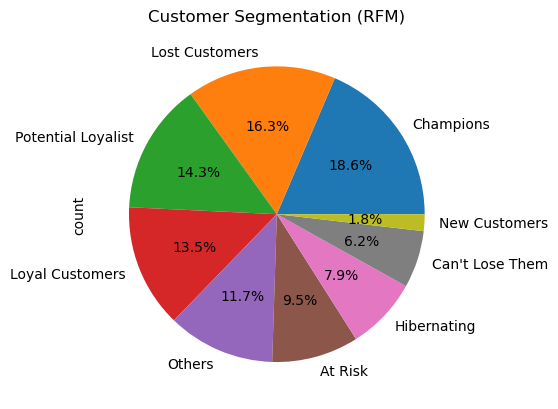

In [14]:
df_RFM['customers_seg'].value_counts().plot.pie(
    title='Customer Segmentation (RFM)', autopct='%1.1f%%'
)

### Key Insights

- **Champions are the largest single segment (18.6%)**, followed by **Lost Customers (16.3%)**, **Potential Loyalists (14.3%)**, and **Loyal Customers (13.5%)**.
- The combination of Champions and Loyal Customers represents **32.1% of customers** and is a logical group for loyalty and repeat-purchase initiatives. Lost Customers represent a similarly substantial reactivation opportunity; the segment chart shows customer shares, not each segment's share of revenue.

## 5. Support Ticket Trends and Service

This section tracks monthly ticket volume and summarizes ticket count, average resolution time, and average satisfaction for each customer. Unresolved tickets are excluded automatically from the resolution-time average because `AVG` ignores `NULL` values.

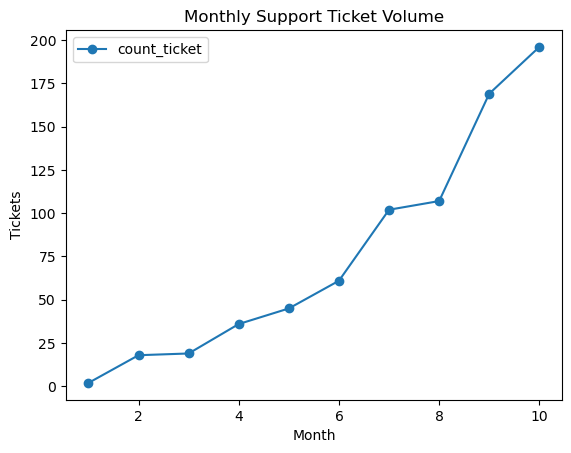

In [15]:
sql = '''SELECT COUNT(*) AS count_ticket,
       MONTH(created_at) AS ticket_month
FROM support_tickets
WHERE YEAR(created_at) = 2026
GROUP BY MONTH(created_at)
ORDER BY ticket_month'''
ticket_df = sql_to_df(sql)
ticket_df
ax = ticket_df.plot(x='ticket_month', y='count_ticket', kind='line', marker='o')
_ = ax.set(title='Monthly Support Ticket Volume', xlabel='Month', ylabel='Tickets')

### Key Insights

- The chart shows a sustained increase in monthly support-ticket volume, reaching **nearly 200 tickets in October**, the highest displayed month.
- The dataset runs only through **October 17, 2026**, so October is a partial month. Before interpreting the rise as worsening service, compare tickets per 100 orders (or customers), normalize by days observed, and review ticket topics and order volumes.

In [16]:
sql = '''SELECT customer_id,
       ROUND(AVG(DATEDIFF(resolved_at, created_at)), 2) AS avg_resolution_days,
       COUNT(*) AS ticket_count,
       ROUND(AVG(satisfaction_score), 2) AS avg_satisfaction
FROM support_tickets
WHERE YEAR(created_at) = 2026
GROUP BY customer_id
ORDER BY customer_id'''
tickets_by_customers = sql_to_df(sql)
tickets_by_customers

,customer_id,avg_resolution_days,ticket_count,avg_satisfaction
0,CUST-10003,5.00,1,5.00
1,CUST-10004,3.00,2,3.00
2,CUST-10009,2.00,1,3.00
3,CUST-10011,0.00,1,5.00
4,CUST-10012,7.00,1,1.00
...,...,...,...,...
534,CUST-11194,3.33,4,2.50
535,CUST-11195,1.50,2,4.50
536,CUST-11196,None,1,0.00
537,CUST-11197,2.00,1,5.00


### Key Insights

- The output summarizes support metrics for **539 customers with at least one ticket**, rather than presenting one row per ticket. Resolution time and satisfaction vary across customers, so a single overall conclusion is not available from the displayed examples alone.
- Some customers have a positive ticket count but a `NULL` average resolution time. These cases do not contribute to SQL's `AVG` resolution calculation, so unresolved tickets should be reported separately rather than allowing the average to hide open cases. Also confirm whether a satisfaction score of `0.00` is a valid rating or a code for missing feedback.

## 6. Churn and Support Contact

The next two tables compare churn composition among customers with at least one support ticket and customers with no support tickets. `pct` is the share of customers in each group, not evidence that support contact caused churn.

### Customers with Support Tickets

In [17]:
customers_churn_tickets = churn_df.merge(tickets_by_customers, on = 'customer_id', how = 'left')
customers_churn_tickets

,customer_id,last_order,recency,is_churned,avg_resolution_days,ticket_count,avg_satisfaction
0,CUST-10000,2026-10-17 20:00:00,0,0,NaN,NaN,NaN
1,CUST-10001,2026-09-28 07:47:09,19,0,NaN,NaN,NaN
2,CUST-10002,2026-08-30 08:02:52,48,0,NaN,NaN,NaN
3,CUST-10003,2026-08-30 14:35:24,48,0,5.00,1.0,5.00
4,CUST-10004,2026-09-30 11:16:43,17,0,3.00,2.0,3.00
...,...,...,...,...,...,...,...
1195,CUST-11195,2026-07-13 21:35:05,96,1,1.50,2.0,4.50
1196,CUST-11196,2026-10-01 02:58:06,16,0,None,1.0,0.00
1197,CUST-11197,2026-09-30 05:14:50,17,0,2.00,1.0,5.00
1198,CUST-11198,2026-08-22 17:25:36,56,0,NaN,NaN,NaN


In [18]:
churn_customers = customers_churn_tickets[customers_churn_tickets['ticket_count'] >= 1]
churn_customers

,customer_id,last_order,recency,is_churned,avg_resolution_days,ticket_count,avg_satisfaction
3,CUST-10003,2026-08-30 14:35:24,48,0,5.00,1.0,5.00
4,CUST-10004,2026-09-30 11:16:43,17,0,3.00,2.0,3.00
9,CUST-10009,2026-09-26 21:17:31,21,0,2.00,1.0,3.00
11,CUST-10011,2026-09-24 23:20:47,23,0,0.00,1.0,5.00
12,CUST-10012,2026-06-11 04:10:24,128,1,7.00,1.0,1.00
...,...,...,...,...,...,...,...
1194,CUST-11194,2026-09-12 23:12:25,35,0,3.33,4.0,2.50
1195,CUST-11195,2026-07-13 21:35:05,96,1,1.50,2.0,4.50
1196,CUST-11196,2026-10-01 02:58:06,16,0,None,1.0,0.00
1197,CUST-11197,2026-09-30 05:14:50,17,0,2.00,1.0,5.00


In [19]:
ticket_customers_summary = churn_customers.groupby('is_churned').agg(
    customer_count=('customer_id', 'nunique')
)
ticket_customers_summary['pct'] = (
    ticket_customers_summary['customer_count']
    / ticket_customers_summary['customer_count'].sum() * 100
)
ticket_customers_summary

,customer_count,pct
is_churned,,
0,447,82.931354
1,92,17.068646


### Customers without Support Tickets

In [20]:
not_churn_customers = customers_churn_tickets[customers_churn_tickets['ticket_count'].isnull()]
not_churn_customers

,customer_id,last_order,recency,is_churned,avg_resolution_days,ticket_count,avg_satisfaction
0,CUST-10000,2026-10-17 20:00:00,0,0,NaN,NaN,NaN
1,CUST-10001,2026-09-28 07:47:09,19,0,NaN,NaN,NaN
2,CUST-10002,2026-08-30 08:02:52,48,0,NaN,NaN,NaN
5,CUST-10005,2026-09-08 01:00:45,39,0,NaN,NaN,NaN
6,CUST-10006,2026-10-03 10:21:01,14,0,NaN,NaN,NaN
...,...,...,...,...,...,...,...
1188,CUST-11188,2026-10-02 08:11:42,15,0,NaN,NaN,NaN
1190,CUST-11190,2026-09-23 08:15:50,24,0,NaN,NaN,NaN
1191,CUST-11191,2026-10-07 21:18:06,10,0,NaN,NaN,NaN
1192,CUST-11192,2026-10-13 08:16:45,4,0,NaN,NaN,NaN


In [21]:
no_ticket_customers_summary = not_churn_customers.groupby('is_churned').agg(
    customer_count=('customer_id', 'nunique')
)
no_ticket_customers_summary['pct'] = (
    no_ticket_customers_summary['customer_count']
    / no_ticket_customers_summary['customer_count'].sum() * 100
)
no_ticket_customers_summary

,customer_count,pct
is_churned,,
0,553,83.66112
1,108,16.33888


### Key Insights

- Among customers with support tickets, **92 of 539 (17.1%)** meet the churn rule. Among customers without tickets, **108 of 661 (16.3%)** meet it—a difference of about **0.7 percentage points**.
- These descriptive rates are close, so ticket presence alone does not clearly distinguish churn risk in this dataset. This does not prove that support experiences have no effect: ticket topic, severity, timing, and resolution are not controlled for here, and no statistical test was performed.

## 7. Notes and Limitations

- The supplied CSVs are synthetic and do not describe a real company or actual customers.
- Churn is defined by the notebook's 70-day inactivity rule; it does not necessarily mean a customer explicitly cancelled an account.
- The support-ticket comparison is descriptive and cannot establish causation.
- The `amount` column contains order values, but the original project does not specify a currency.
- The SQL uses MySQL 8+ features such as CTEs and window functions. This notebook was not executed end-to-end in this environment because a MySQL server and `mysql-connector-python` were unavailable. Old stored outputs were cleared so they are not mistaken for results from the supplied CSVs.
- The focused logic changes are the support-ticket aggregation fixes, consistent recency naming/filtering, deterministic RFM tie-breakers, safer database connection cleanup, and aligning the estimated churn date to the 70-day churn rule. The unused `churn_month` column assignment was removed because the chart groups on `churn_date` instead.

## Key Findings & Recommendations

### Key Findings

1. **Inactivity-based churn:** 200 of 1,200 customers (16.7%) cross the notebook's more-than-70-day inactivity threshold. The average gap between consecutive orders is 30 days, but the threshold remains an operational definition rather than confirmed customer loss.
2. **Timing of churn flags:** August and September account for 96 estimated threshold crossings (48% of the flagged group), making this period a useful focus for reviewing the last-purchase timing and outreach process.
3. **Cohort activity:** Second-month active counts are lower than first-month cohort sizes in every cohort with a second-month observation. The size of the change varies, and the table reports counts rather than normalized retention rates.
4. **RFM mix:** Champions make up 18.6% of customers, while Lost Customers account for 16.3%. This points to distinct retention and reactivation groups; these percentages describe customer counts, not revenue contribution.
5. **Support monitoring:** Monthly ticket volume rises across the displayed period and reaches nearly 200 in October, although the data only cover October through the 17th. Churn-flag rates are similar for customers with tickets (17.1%) and without tickets (16.3%), so ticket presence by itself is not a clear churn separator in this comparison.

### Recommendations

1. **Test a staged re-engagement cadence.** Use the 30-day average purchase gap as a starting point for a reminder, then test another contact before the 70-day threshold. Compare repeat-purchase rates against a holdout group before treating the cadence as effective.
2. **Tailor retention actions by RFM segment.** Prioritize loyalty and repeat-purchase benefits for Champions and Loyal Customers, and test targeted win-back messages for Lost Customers. Evaluate results by incremental repeat orders and revenue, not campaign engagement alone.
3. **Add normalized cohort retention rates.** Divide each cohort's active-customer count in month 2, 3, and later periods by its month-1 cohort size. Compare only equivalent cohort ages and investigate whether lower rates persist across several cohorts before attributing them to a business change.
4. **Monitor support demand relative to activity.** Track tickets per 100 orders or customers and use daily rates for partial months. Break the increase down by issue type, product/category, and fulfillment status to identify where operational investigation is most warranted.
5. **Improve service-resolution monitoring.** Track open/unresolved ticket counts and resolution-time percentiles alongside averages, then examine satisfaction by issue type and resolution duration. Verify the meaning of `0.00` satisfaction scores before treating them as genuine low ratings.

> **Scope note:** The notebook states that the supplied data are synthetic. These findings demonstrate an analysis workflow and should not be presented as actual company performance.